# Word2Vec

This notebook trains a skip-gram model on ABC (Australian Broadcasting Corporation) science articles. Given a word, the model learns to predict which words are likely to appear nearby. We'll look at both its predictions and the word embeddings it learns along the way.

In [1]:
from itertools import pairwise

import matplotlib.pyplot as plt
import nltk
import numpy as np
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

import word2vec as w2v

BLAS_THREADS = 4
threadpool_limits(limits=BLAS_THREADS, user_api='blas');

nltk.download(['abc', 'punkt_tab', 'stopwords'], quiet=True);

## Corpus and context pairs

We split the corpus by sentence into training, validation, and test sets. The vocabulary contains words that appear at least five times in the training set. We report how much of the validation and test text this vocabulary covers, then pair each word with neighbors up to two positions away on either side.

In [2]:
corpus = nltk.corpus.abc.raw('science.txt')
assert isinstance(corpus, str)

sentences = nltk.sent_tokenize(corpus)
tokenized_sentences = [w2v.tokenize(sentence) for sentence in sentences]

# Split points at 0.7 and 0.85 give a 70/15/15 train/validation/test split
train_sentences, val_sentences, test_sentences = w2v.random_split(
    tokenized_sentences, (0.70, 0.85), seed=42
)
word_to_id, id_to_word, _ = w2v.build_vocab(train_sentences, min_count=5)

coverage_splits = (
    ('Validation coverage', val_sentences),
    ('Test coverage', test_sentences),
)

print(f'Training vocabulary  {len(word_to_id):,} words')
for label, split_sentences in coverage_splits:
    token_coverage, type_coverage = w2v.vocab_coverage(split_sentences, word_to_id)
    print(f'\n{label:<21}{token_coverage:.2%} of word occurrences')
    print(f'{"":21}{type_coverage:.2%} of distinct words')

Training vocabulary  5,359 words

Validation coverage  89.05% of word occurrences
                     48.72% of distinct words

Test coverage        89.66% of word occurrences
                     49.80% of distinct words


In [3]:
WINDOW_SIZE = 2

train_pairs = w2v.generate_pairs(train_sentences, word_to_id, WINDOW_SIZE)
val_pairs = w2v.generate_pairs(val_sentences, word_to_id, WINDOW_SIZE)
test_pairs = w2v.generate_pairs(test_sentences, word_to_id, WINDOW_SIZE)

print(f'Training pairs    {len(train_pairs):,}')
print(f'Validation pairs  {len(val_pairs):,}')
print(f'Test pairs        {len(test_pairs):,}')

Training pairs    788,518
Validation pairs  161,286
Test pairs        164,442


## Training and validation

We train word embeddings with 64 dimensions and plot the mean cross-entropy over 20 training epochs. Epoch 0 shows the loss at initialization. During training, we average loss across batches and evaluate validation loss at the end of each epoch. We keep the weights from the epoch with the lowest validation loss.

In [4]:
BATCH_SIZE = 64

model = w2v.Word2Vec(word_to_id, id_to_word, embedding_dim=64, seed=42)

initial_input_embeddings = model.input_embeddings.copy()
initial_train_loss = model.evaluate(train_pairs, batch_size=BATCH_SIZE)
initial_val_loss = model.evaluate(val_pairs, batch_size=BATCH_SIZE)
initial_test_loss = model.evaluate(test_pairs, batch_size=BATCH_SIZE)

train_loss_history, val_loss_history = model.train(
    train_pairs,
    val_pairs,
    epochs=20,
    batch_size=BATCH_SIZE,
    learning_rate=0.7,
    restore_best_weights=True,
)

# train() restored weights from the epoch with the lowest validation loss
final_test_loss = model.evaluate(test_pairs, batch_size=BATCH_SIZE)

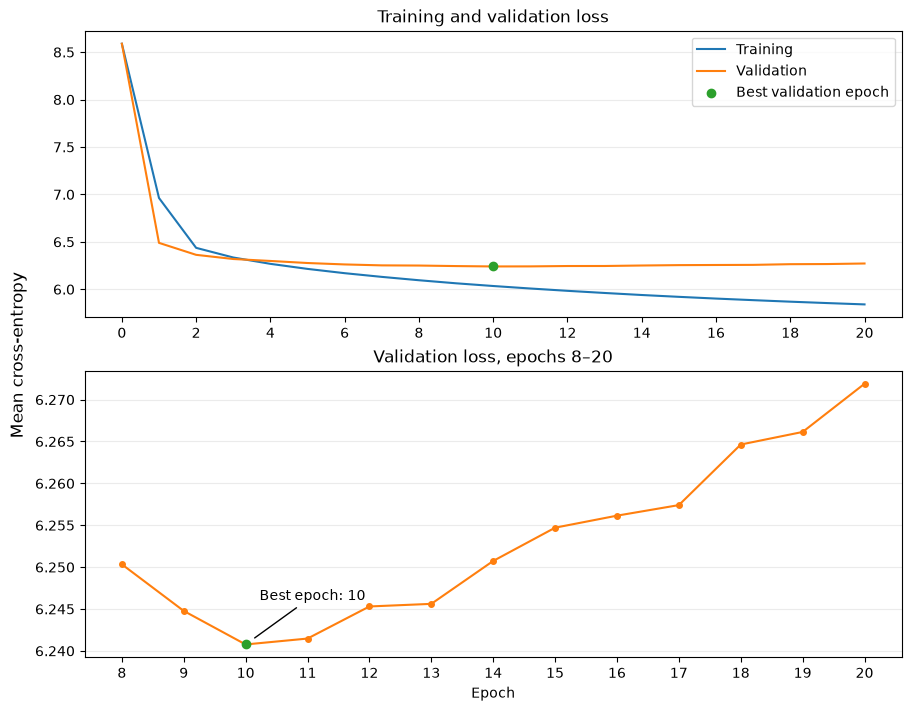

Test mean cross-entropy before training  8.5889
Test mean cross-entropy after training   6.2313
Change (after − before)                 -2.3576


In [5]:
last_epoch = len(val_loss_history)
best_epoch = int(np.argmin(val_loss_history)) + 1
best_val_loss = val_loss_history[best_epoch - 1]

epochs = range(last_epoch + 1)
training_losses = [initial_train_loss, *train_loss_history]
validation_losses = [initial_val_loss, *val_loss_history]

fig, (full_ax, zoom_ax) = plt.subplots(2, 1, figsize=(9, 7), layout='constrained')
best_epoch_color = 'tab:green'

full_ax.plot(epochs, training_losses, color='tab:blue', label='Training')
full_ax.plot(epochs, validation_losses, color='tab:orange', label='Validation')
full_ax.scatter(
    best_epoch,
    best_val_loss,
    color=best_epoch_color,
    zorder=3,
    label='Best validation epoch',
)
full_ax.set(title='Training and validation loss', xticks=epochs[::2])
full_ax.legend()

zoom_ax.plot(
    epochs[8:], validation_losses[8:], color='tab:orange', marker='o', markersize=4
)
zoom_ax.scatter(best_epoch, best_val_loss, color=best_epoch_color, zorder=3)
zoom_ax.annotate(
    f'Best epoch: {best_epoch}',
    (best_epoch, best_val_loss),
    xytext=(10, 32),
    textcoords='offset points',
    arrowprops={'arrowstyle': '-', 'shrinkB': 8},
)
zoom_ax.set(
    title=f'Validation loss, epochs 8–{last_epoch}',
    xlabel='Epoch',
    xticks=epochs[8:],
)

for ax in (full_ax, zoom_ax):
    ax.grid(axis='y', alpha=0.25)

fig.supylabel('Mean cross-entropy')
plt.show()

test_loss_change = final_test_loss - initial_test_loss
print(f'Test mean cross-entropy before training  {initial_test_loss:.4f}')
print(f'Test mean cross-entropy after training   {final_test_loss:.4f}')
print(f'Change (after − before)                 {test_loss_change:+.4f}')

## Embedding neighbors and predicted contexts

For each example word, we look at both its closest neighbors by cosine similarity and the context words the model expects to see nearby. We filter the contexts to remove stopwords to make meaningful predictions easier to see.

In [6]:
def format_contexts(contexts):
    return ', '.join(f'`{word}` ({probability:.1%})' for word, probability in contexts)


query_words = ('planet', 'climate', 'cancer', 'telescope')
excluded_contexts = set(nltk.corpus.stopwords.words('english')) | {
    'st',
    'nd',
    'rd',
    'th',
}
rows = [
    '| Center | Cosine neighbors | Top contexts | Top content words |',
    '|---|---|---|---|',
]

for word in query_words:
    neighbors = ', '.join(
        f'`{neighbor}` ({similarity:.2f})'
        for neighbor, similarity in model.most_similar(word, k=5)
    )

    # Rank full vocab so we can take the top three both before and after filtering
    ranked_contexts = model.predict_context(word, k=len(word_to_id))
    top_contexts = format_contexts(ranked_contexts[:3])
    content_contexts = [
        (context, probability)
        for context, probability in ranked_contexts
        if context not in excluded_contexts
    ][:3]
    top_content = format_contexts(content_contexts)
    rows.append(f'| `{word}` | {neighbors} | {top_contexts} | {top_content} |')

display(Markdown('\n'.join(rows)))

| Center | Cosine neighbors | Top contexts | Top content words |
|---|---|---|---|
| `planet` | `giant` (0.62), `star` (0.61), `ring` (0.60), `object` (0.58), `spring` (0.58) | `the` (8.9%), `a` (6.4%), `of` (3.9%) | `says` (1.4%), `earth` (0.9%), `first` (0.6%) |
| `climate` | `warming` (0.60), `global` (0.53), `significant` (0.52), `evolutionary` (0.52), `induced` (0.51) | `change` (20.0%), `of` (4.8%), `on` (4.0%) | `change` (20.0%), `global` (2.3%), `says` (1.1%) |
| `cancer` | `lung` (0.61), `attack` (0.58), `heart` (0.58), `infectious` (0.57), `alzheimer's` (0.53) | `breast` (6.8%), `cells` (5.1%), `and` (4.3%) | `breast` (6.8%), `cells` (5.1%), `disease` (1.1%) |
| `telescope` | `mission` (0.58), `service` (0.57), `measurement` (0.54), `fabric` (0.53), `fleet` (0.53) | `the` (8.0%), `space` (7.0%), `a` (5.8%) | `space` (7.0%), `hubble` (3.3%), `new` (1.6%) |

## Prediction example

We take an example sentence from the corpus and walk through it word by word. For each word, we rank possible context words and highlight cases where the next word appears in the top three. Skip-gram learns from words on both sides of the center word. For example, "cells" ranks first for "stem", and "stem" also ranks first for "cells."

In [7]:
# These indices select the stem cell sentence and the surrounding text shown in the quote
excerpt_start, excerpt_end = 1058291, 1058447
sentence_start, sentence_end = 1058338, 1058428

before = corpus[excerpt_start:sentence_start].strip()
demo_sentence = corpus[sentence_start:sentence_end]
after = corpus[sentence_end:excerpt_end].strip()

display(
    Markdown(
        f'`corpus[{excerpt_start}:{excerpt_end}]`\n\n'
        f'> … {before} **{demo_sentence}** {after} …\n\n\u200b'
    )
)

demo_tokens = w2v.tokenize(demo_sentence)

rows = [
    '| Current word | Top three context guesses | Actual next word | Rank |',
    '|---|---|---|---:|',
]

for current_word, next_word in pairwise(demo_tokens):
    ranked_contexts = model.predict_context(current_word, k=len(word_to_id))
    guesses = format_contexts(ranked_contexts[:3])
    context_words = [word for word, _ in ranked_contexts]
    rank = context_words.index(next_word) + 1
    actual = f'`{next_word}`'
    rank_text = f'{rank:,}'
    if rank <= 3:
        actual = f'**{actual}**'
        rank_text = f'**{rank_text}**'
    rows.append(f'| `{current_word}` | {guesses} | {actual} | {rank_text} |')

display(Markdown('\n'.join(rows)))

`corpus[1058291:1058447]`

> … The trial is expected to wrap up next month. **Stem cells are master cells that have the potential to develop into any organ of the body.** Scientists believe …

​

| Current word | Top three context guesses | Actual next word | Rank |
|---|---|---|---:|
| `stem` | `cells` (17.9%), `cell` (9.2%), `embryonic` (6.8%) | **`cells`** | **1** |
| `cells` | `stem` (7.5%), `the` (6.0%), `that` (4.3%) | `are` | 9 |
| `are` | `to` (5.7%), `the` (5.6%), `they` (3.5%) | `master` | 1,411 |
| `master` | `cells` (26.9%), `the` (9.2%), `to` (8.8%) | **`cells`** | **1** |
| `cells` | `stem` (7.5%), `the` (6.0%), `that` (4.3%) | **`that`** | **3** |
| `that` | `the` (4.1%), `is` (2.9%), `found` (2.0%) | `have` | 12 |
| `have` | `to` (6.6%), `the` (4.1%), `been` (3.8%) | **`the`** | **2** |
| `the` | `of` (7.6%), `in` (4.3%), `to` (3.0%) | `potential` | 271 |
| `potential` | `to` (13.3%), `the` (8.6%), `for` (8.3%) | **`to`** | **1** |
| `to` | `the` (4.0%), `be` (1.8%), `have` (1.5%) | `develop` | 31 |
| `develop` | `to` (15.2%), `a` (4.2%), `and` (2.6%) | `into` | 8 |
| `into` | `the` (6.1%), `a` (4.0%), `it` (1.9%) | `any` | 73 |
| `any` | `of` (6.1%), `to` (3.6%), `and` (2.9%) | `organ` | 1,888 |
| `organ` | `the` (7.3%), `and` (5.9%), `to` (5.5%) | `of` | 8 |
| `of` | `the` (13.0%), `a` (4.1%), `university` (2.3%) | **`the`** | **1** |
| `the` | `of` (7.6%), `in` (4.3%), `to` (3.0%) | `body` | 145 |

## Visualizing word embeddings

We can use PCA to project normalized word embeddings onto a 2D plot. We plot the same example words before and after training. Colors mark the topics we assigned to the words. Before training, we can see words from all three topics are mixed together. After training, they form visible groups.

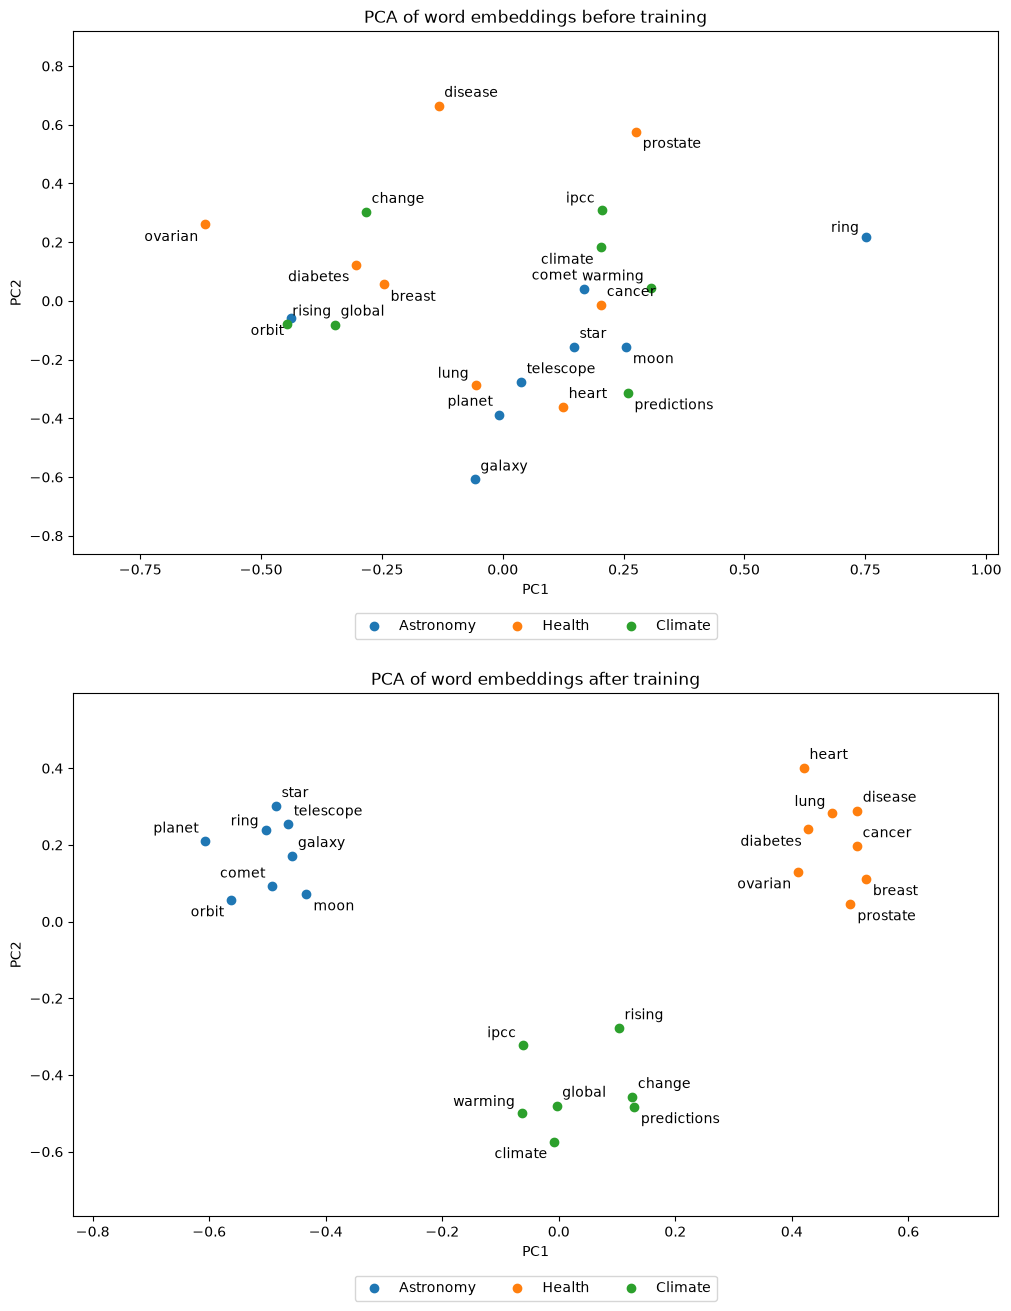

In [8]:
word_groups = {
    'Astronomy': (
        'planet',
        'star',
        'orbit',
        'telescope',
        'galaxy',
        'moon',
        'comet',
        'ring',
    ),
    'Health': (
        'cancer',
        'lung',
        'breast',
        'disease',
        'heart',
        'ovarian',
        'prostate',
        'diabetes',
    ),
    'Climate': (
        'climate',
        'warming',
        'global',
        'change',
        'ipcc',
        'rising',
        'predictions',
    ),
}

words = [word for group in word_groups.values() for word in group]
word_ids = [word_to_id[word] for word in words]

before_vectors = initial_input_embeddings[word_ids]
after_vectors = model.input_embeddings[word_ids]

before_points = w2v.pca_2d(before_vectors, normalize=True)
after_points = w2v.pca_2d(after_vectors, normalize=True)

label_offsets = {
    'planet': (-5, 4),
    'orbit': (-5, -4),
    'ring': (-5, 1),
    'comet': (-5, 4),
    'moon': (5, -4),
    'lung': (-5, 3),
    'diabetes': (-5, -4),
    'ovarian': (-5, -4),
    'breast': (5, -4),
    'prostate': (5, -4),
    'warming': (-5, 3),
    'climate': (-5, -4),
    'ipcc': (-5, 3),
    'predictions': (5, -4),
}

fig, axes = plt.subplots(
    2, 1, figsize=(10, 13), layout='constrained', gridspec_kw={'hspace': 0.05}
)

for ax, title, projection in zip(
    axes,
    ('PCA of word embeddings before training', 'PCA of word embeddings after training'),
    (before_points, after_points),
):
    coordinates = dict(zip(words, projection))

    for label, group in word_groups.items():
        points = np.array([coordinates[word] for word in group])
        ax.scatter(points[:, 0], points[:, 1], label=label)

        for word, point in zip(group, points):
            dx, dy = label_offsets.get(word, (4, 4))
            ax.annotate(
                word,
                point,
                xytext=(dx, dy),
                textcoords='offset points',
                ha='right' if dx < 0 else 'left',
                va='top' if dy < 0 else 'bottom',
            )

    ax.set(title=title, xlabel='PC1', ylabel='PC2')
    ax.margins(0.2)
    ax.legend(
        loc='upper center',
        bbox_to_anchor=(0.5, -0.10),
        ncols=len(word_groups),
    )

plt.show()